# 1. Import libraries

In [25]:
import tensorflow as tf 
from tensorflow.keras import layers, models, datasets
import matplotlib.pyplot as plt 
import numpy as np 
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 2. Downloading and preparing the dataset 

In [26]:
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

d:\Github\deep-learning-for-computer-vision\py-env\Lib\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = cPickle.load(f, encoding="bytes")


In [27]:
x_train

array([[[[ 59,  62,  63],
         [ 43,  46,  45],
         [ 50,  48,  43],
         ...,
         [158, 132, 108],
         [152, 125, 102],
         [148, 124, 103]],

        [[ 16,  20,  20],
         [  0,   0,   0],
         [ 18,   8,   0],
         ...,
         [123,  88,  55],
         [119,  83,  50],
         [122,  87,  57]],

        [[ 25,  24,  21],
         [ 16,   7,   0],
         [ 49,  27,   8],
         ...,
         [118,  84,  50],
         [120,  84,  50],
         [109,  73,  42]],

        ...,

        [[208, 170,  96],
         [201, 153,  34],
         [198, 161,  26],
         ...,
         [160, 133,  70],
         [ 56,  31,   7],
         [ 53,  34,  20]],

        [[180, 139,  96],
         [173, 123,  42],
         [186, 144,  30],
         ...,
         [184, 148,  94],
         [ 97,  62,  34],
         [ 83,  53,  34]],

        [[177, 144, 116],
         [168, 129,  94],
         [179, 142,  87],
         ...,
         [216, 184, 140],
        

In [28]:
x_train.shape

(50000, 32, 32, 3)

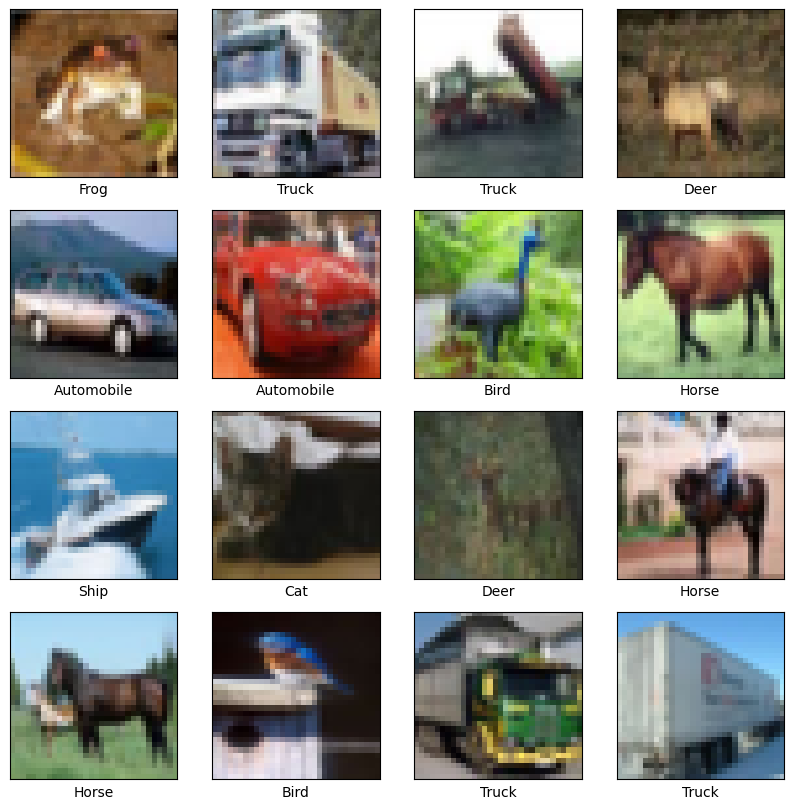

In [36]:
class_names = ['Airplane','Automobile','Bird','Cat','Deer','Dog','Frog','Horse','Ship','Truck']

plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[np.argmax(y_train[i])])
plt.show()

# 2. Preprocessing and normalizing the data 

In [29]:
rows, cols = 32, 32 
input_shape=(rows, cols, 3) 
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train = x_train/255.0 
x_test = x_test/255.0 
y_train=tf.keras.utils.to_categorical(y_train, 10)

In [30]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(50000, 10))

# 3. Build model 

In [31]:
def build_lenet1(input_shape):
    model = models.Sequential([
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh', input_shape=input_shape),
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)), 
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh'), 
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)),
        layers.Dense(units=120, activation='tanh'),
        layers.Flatten(),
        layers.Dense(units=84, activation='tanh'),
        layers.Dense(units=10, activation='softmax')
    ])
    return model 

In [32]:
lenet1 = build_lenet1(input_shape)
lenet1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
lenet1.summary()

d:\Github\deep-learning-for-computer-vision\py-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 14, 14, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 10, 10, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 5, 5, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5, 5, 120)      │         3,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 84)             │       252,084 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 284,958 (1.09 MB)

 Trainable params: 284,958 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
epochs = 20 
history1 = lenet1.fit(x_train, y_train, 
                     epochs=epochs, 
                     batch_size=128, 
                     callbacks=[early_stop, reduce_lr], 
                     validation_split=0.2, 
                     verbose=2)

Epoch 1/20
313/313 - 7s - 23ms/step - accuracy: 0.3498 - loss: 1.8452 - val_accuracy: 0.3932 - val_loss: 1.7395 - learning_rate: 0.0010
Epoch 2/20
313/313 - 6s - 19ms/step - accuracy: 0.4225 - loss: 1.6507 - val_accuracy: 0.4370 - val_loss: 1.5960 - learning_rate: 0.0010
Epoch 3/20
313/313 - 6s - 20ms/step - accuracy: 0.4662 - loss: 1.5144 - val_accuracy: 0.4723 - val_loss: 1.5015 - learning_rate: 0.0010
Epoch 4/20
313/313 - 6s - 18ms/step - accuracy: 0.4951 - loss: 1.4356 - val_accuracy: 0.4841 - val_loss: 1.4716 - learning_rate: 0.0010
Epoch 5/20
313/313 - 5s - 17ms/step - accuracy: 0.5131 - loss: 1.3777 - val_accuracy: 0.4943 - val_loss: 1.4303 - learning_rate: 0.0010
Epoch 6/20
313/313 - 10s - 33ms/step - accuracy: 0.5312 - loss: 1.3227 - val_accuracy: 0.5091 - val_loss: 1.3964 - learning_rate: 0.0010
Epoch 7/20
313/313 - 6s - 19ms/step - accuracy: 0.5534 - loss: 1.2704 - val_accuracy: 0.5246 - val_loss: 1.3471 - learning_rate: 0.0010
Epoch 8/20
313/313 - 5s - 17ms/step - accuracy:

In [34]:
if len(y_test.shape) != 2 or y_test.shape[1] != 10:
  y_test = tf.keras.utils.to_categorical(y_test, 10)

loss ,acc= lenet1.evaluate(x_test, y_test, verbose=0)
print('Accuracy : ', acc)
print('Loss: ', loss)

Accuracy :  0.569100022315979
Loss:  1.2526848316192627


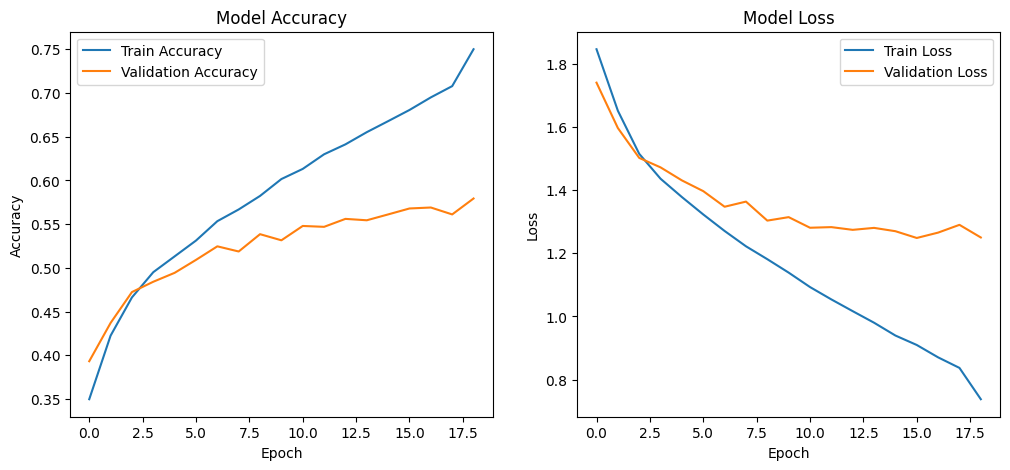

In [ ]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history1.history['accuracy'], label='Train Accuracy')
plt.plot(history1.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history1.history['loss'], label='Train Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


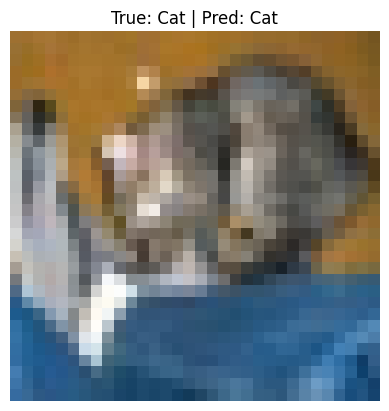

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


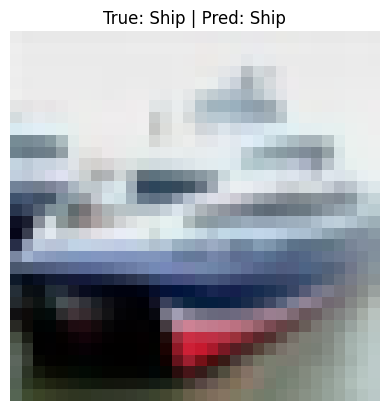

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


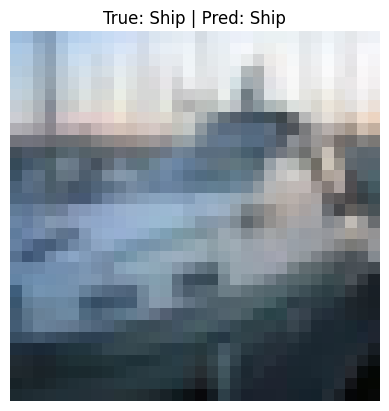

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


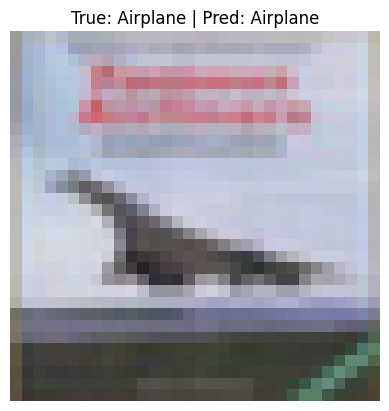

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


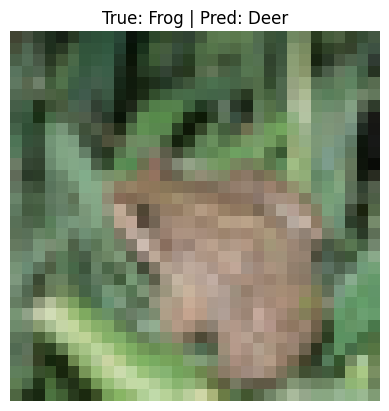

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


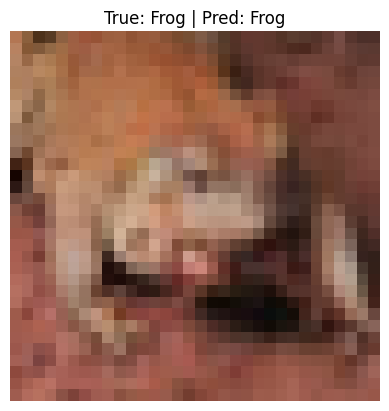

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


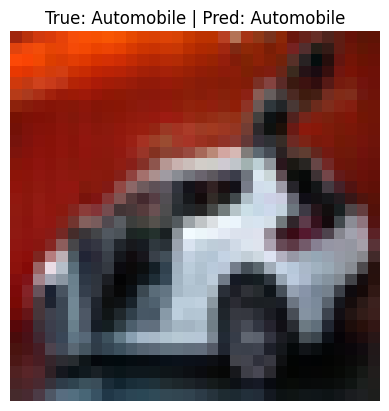

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


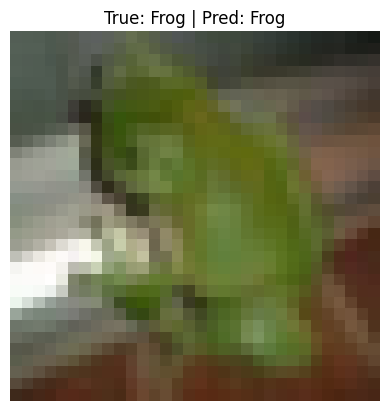

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


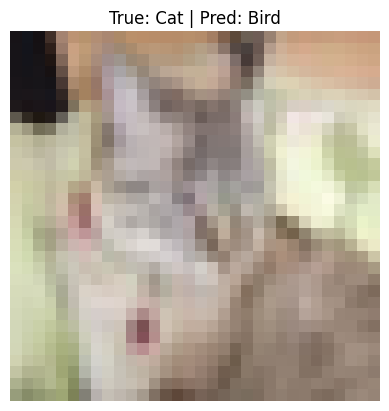

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


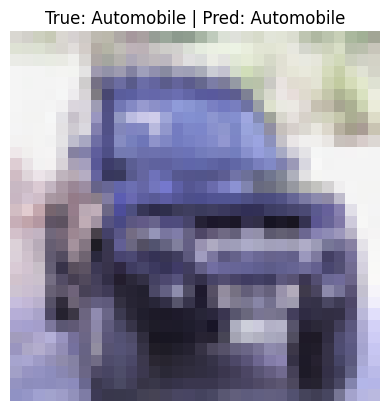

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


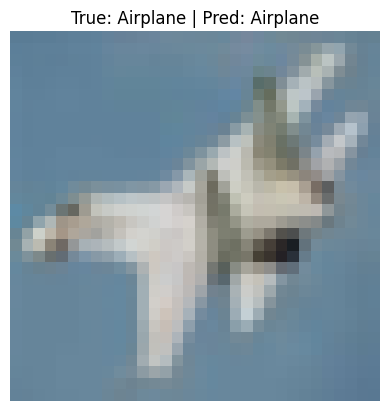

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


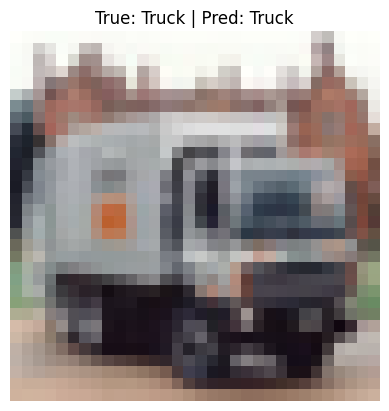

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


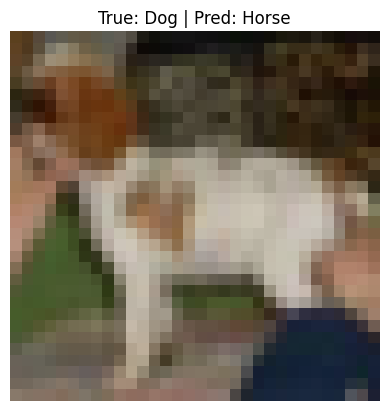

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


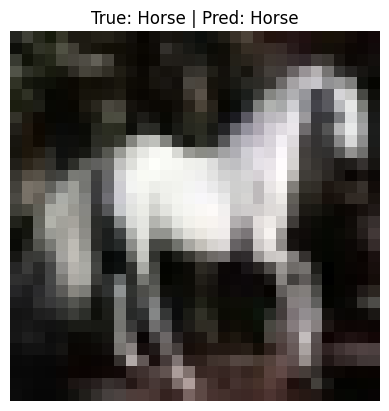

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


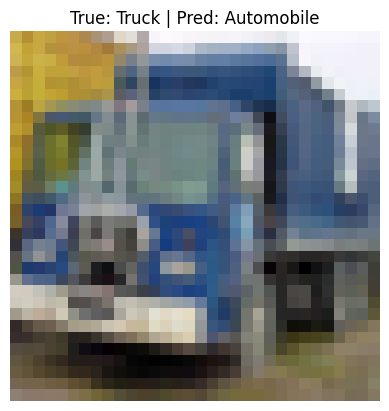

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


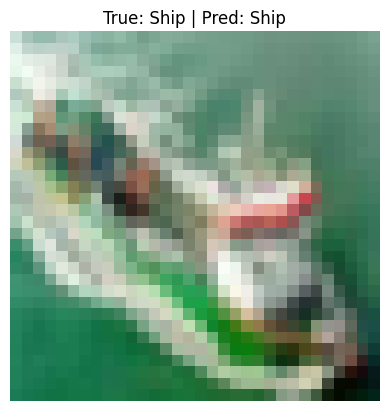

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


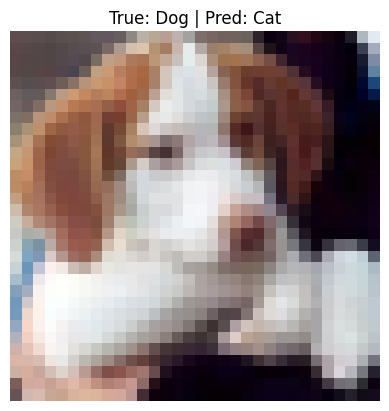

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


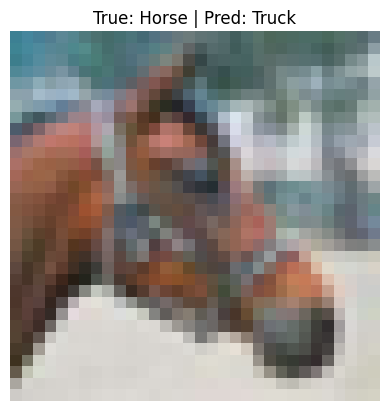

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


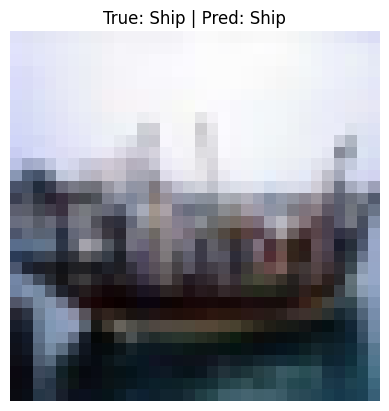

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


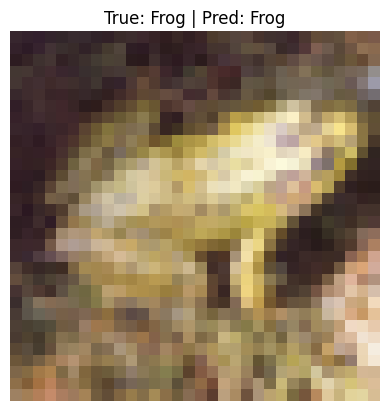

In [38]:
def plot_predictions(index):
    img = x_test[index]
    true_label = class_names[np.argmax(y_test[index])]
    pred_probs = lenet1.predict(np.expand_dims(img, axis=0))
    pred_label = class_names[np.argmax(pred_probs)]
    
    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions(i)

In [39]:
lenet1.save("../data/models/lenet1_cifar10.h5") 

In [40]:
def build_lenet2(input_shape):
    model = models.Sequential([
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh', input_shape=input_shape),
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)), 
        layers.Conv2D(filters=32, strides=(1,1), kernel_size=(5,5), activation='tanh'), 
        layers.AveragePooling2D(pool_size=(2,2), strides=(2,2)),
        layers.Dense(units=256, activation='tanh'),
        layers.Flatten(),
        layers.Dense(units=128, activation='tanh'),
        layers.Dense(units=10, activation='softmax')
    ])
    return model 

In [41]:
lenet2 = build_lenet2(input_shape)
lenet2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
lenet2.summary()

d:\Github\deep-learning-for-computer-vision\py-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 14, 14, 32)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 10, 10, 32)     │        25,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 5, 5, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5, 5, 256)      │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       819,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 857,130 (3.27 MB)

 Trainable params: 857,130 (3.27 MB)

 Non-trainable params: 0 (0.00 B)

In [42]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)
epochs = 20 
history2 = lenet2.fit(x_train, y_train, 
                     epochs=epochs, 
                     batch_size=128, 
                     callbacks=[early_stop, reduce_lr], 
                     validation_split=0.2, 
                     verbose=2)

Epoch 1/20
313/313 - 8s - 25ms/step - accuracy: 0.3513 - loss: 1.8369 - val_accuracy: 0.3896 - val_loss: 1.7386 - learning_rate: 0.0010
Epoch 2/20
313/313 - 7s - 21ms/step - accuracy: 0.4146 - loss: 1.6744 - val_accuracy: 0.4112 - val_loss: 1.6523 - learning_rate: 0.0010
Epoch 3/20
313/313 - 7s - 22ms/step - accuracy: 0.4582 - loss: 1.5324 - val_accuracy: 0.4617 - val_loss: 1.5240 - learning_rate: 0.0010
Epoch 4/20
313/313 - 7s - 23ms/step - accuracy: 0.4906 - loss: 1.4355 - val_accuracy: 0.4891 - val_loss: 1.4570 - learning_rate: 0.0010
Epoch 5/20
313/313 - 7s - 23ms/step - accuracy: 0.5157 - loss: 1.3708 - val_accuracy: 0.4988 - val_loss: 1.4206 - learning_rate: 0.0010
Epoch 6/20
313/313 - 8s - 24ms/step - accuracy: 0.5310 - loss: 1.3254 - val_accuracy: 0.5000 - val_loss: 1.4329 - learning_rate: 0.0010
Epoch 7/20
313/313 - 7s - 24ms/step - accuracy: 0.5468 - loss: 1.2838 - val_accuracy: 0.5147 - val_loss: 1.3849 - learning_rate: 0.0010
Epoch 8/20
313/313 - 7s - 22ms/step - accuracy: 

In [44]:
if len(y_test.shape) != 2 or y_test.shape[1] != 10:
  y_test = tf.keras.utils.to_categorical(y_test, 10)

loss ,acc= lenet2.evaluate(x_test, y_test, verbose=0)
print('Accuracy : ', acc)
print('Loss: ', loss)

Accuracy :  0.5504000186920166
Loss:  1.294864296913147


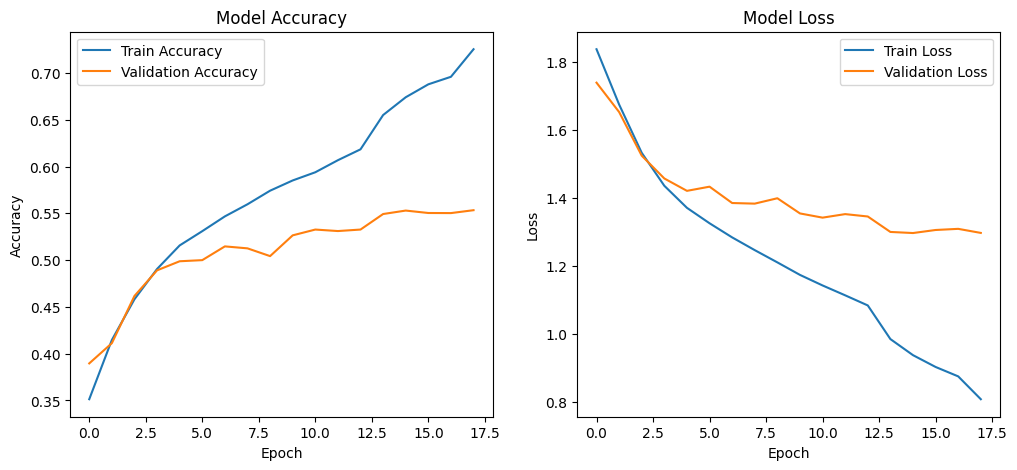

In [45]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(history2.history['accuracy'], label='Train Accuracy')
plt.plot(history2.history['val_accuracy'], label='Validation Accuracy')
plt.title("Model Accuracy")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history2.history['loss'], label='Train Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


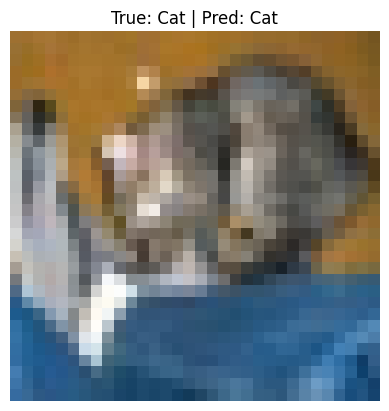

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


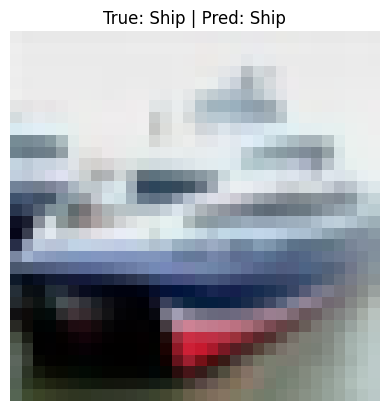

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


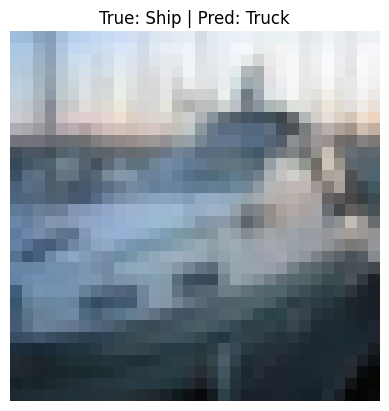

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


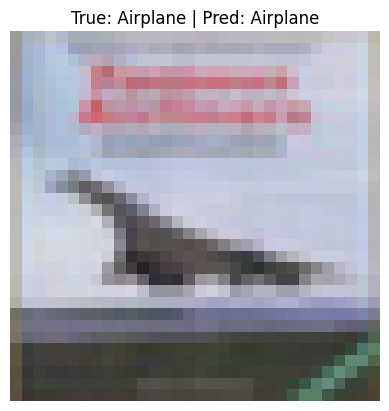

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


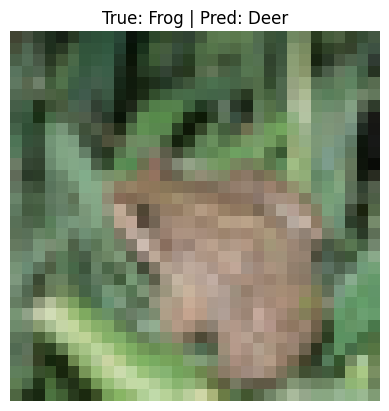

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


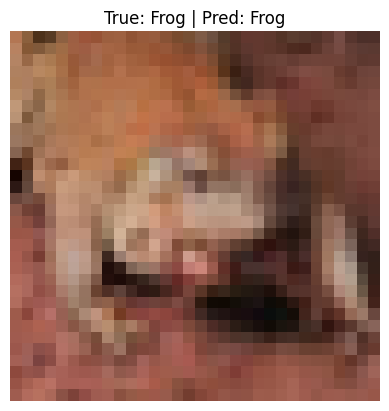

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


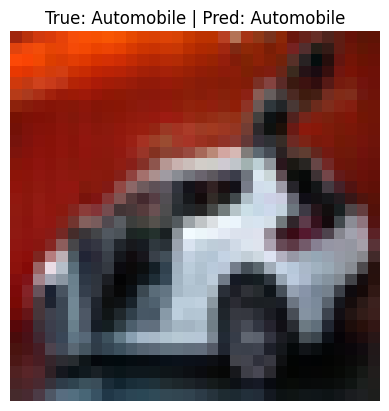

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


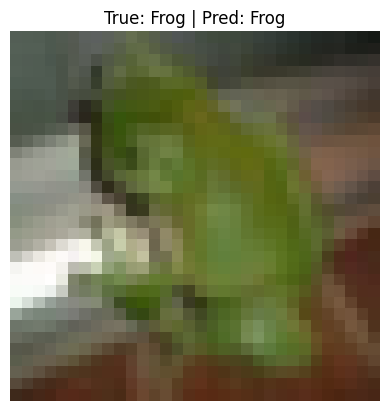

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


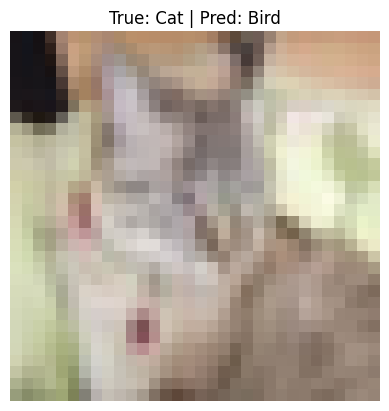

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step


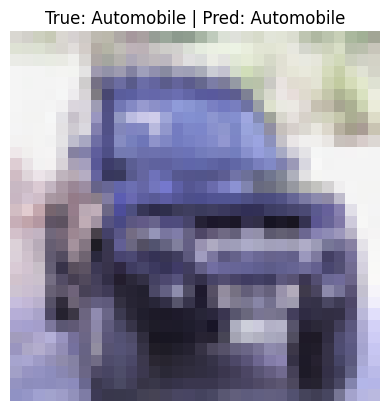

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


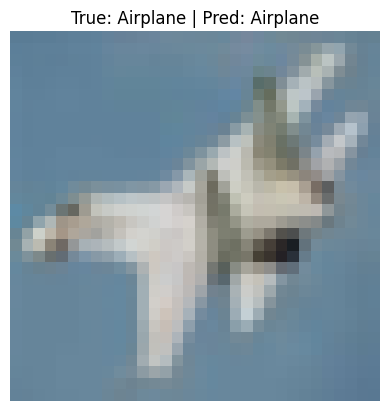

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


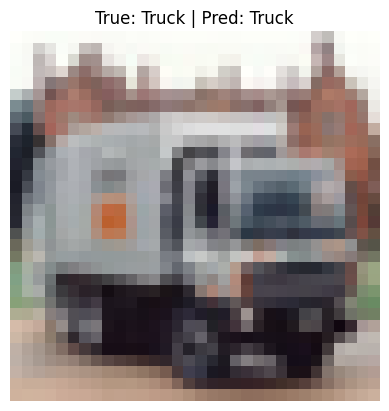

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


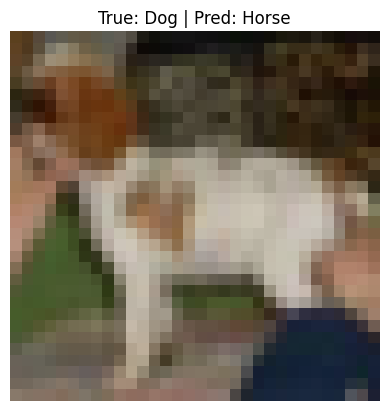

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


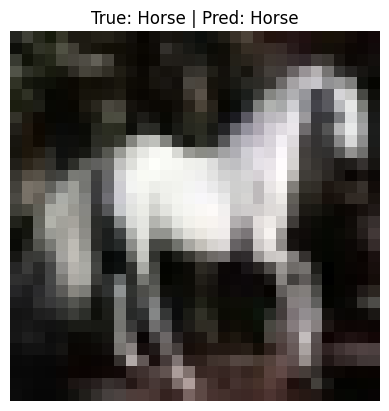

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


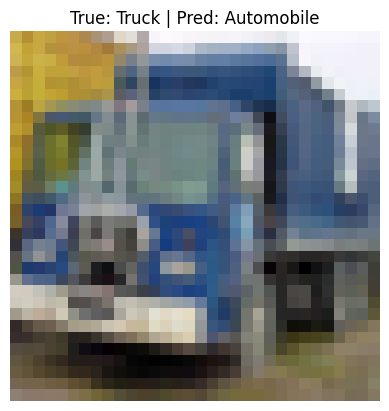

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


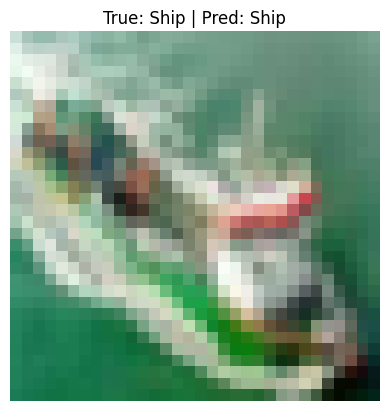

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


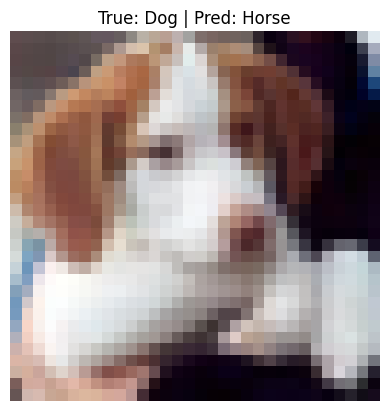

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


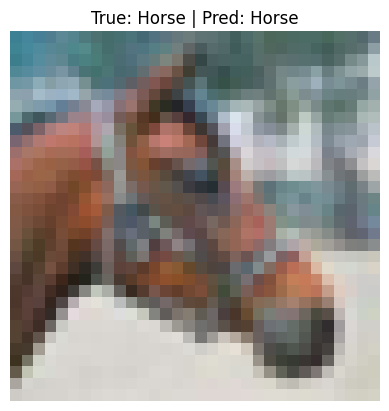

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


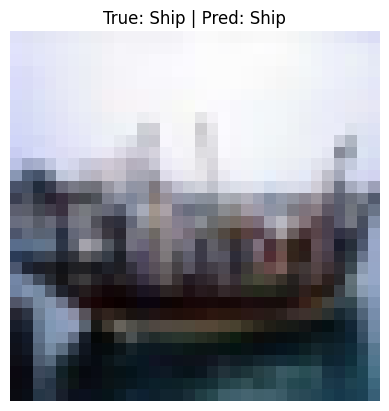

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


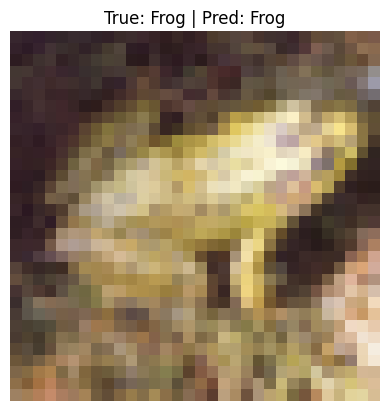

In [46]:
def plot_predictions2(index):
    img = x_test[index]
    true_label = class_names[np.argmax(y_test[index])]
    pred_probs = lenet2.predict(np.expand_dims(img, axis=0))
    pred_label = class_names[np.argmax(pred_probs)]
    
    plt.imshow(img)
    plt.title(f"True: {true_label} | Pred: {pred_label}")
    plt.axis('off')
    plt.show()


for i in range(20):
    plot_predictions2(i)